# Daily challenge — Strategic Superstore analysis

Octopus Week 2 · Day 4

[Assignment](https://octopus.developers.institute/courses/collection/254/course/812/section/1705/chapter/4339)

Run cells in order. Source datasets are in `../data`; see the root README for setup and provenance.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'analysis_utils.py').exists())
sys.path.insert(0, str(ROOT))
sns.set_theme(style='whitegrid')
def load(kind, filename=None, **kwargs):
    files = list((ROOT / 'data' / kind).rglob(filename or '*.csv'))
    if len(files) != 1:
        raise ValueError(f'Select an unambiguous data file: {files}')
    return pd.read_csv(files[0], **kwargs)
def savefig(name):
    target = ROOT / 'figures'
    target.mkdir(exist_ok=True)
    plt.tight_layout()
    plt.savefig(target / (name + '.png'), dpi=140, bbox_inches='tight')
    plt.show()


## Business questions and scope
Which categories and states contribute sales, which products contribute profit, and which observed discount bands coincide with losses? Analyze order lines, not unique orders or customers. Dataset currency is USD. Recommendations are diagnostic hypotheses; discount allocation is not randomized, so correlation does not establish the effect of changing prices.

In [2]:
raw=load('superstore',encoding='cp1252')
print('Shape:',raw.shape);print('Columns:',raw.columns.tolist());raw.info()
display(raw.head(3));display(raw.describe());display(raw.isna().sum().to_frame('missing'))
print('Duplicate full rows:',raw.duplicated().sum())

Shape: (9994, 21)
Columns: ['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']
<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.0,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0.0,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2,0.0,6.8714


,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


,missing
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0


Duplicate full rows: 0


## Preparation and feature engineering
Remove exact duplicate records only. Preserve repeated orders because one order may contain multiple lines. Parse US-format dates explicitly. Keep missing postal codes unknown rather than inventing location 0; they are not used for these aggregations. Sales=0 produces an undefined margin (NaN), not infinity. The overall business margin is total profit / total sales, not an unweighted average of line margins.

In [3]:
from analysis_utils import prepare_superstore
df=prepare_superstore(raw)
assert df['Order Date'].notna().all()
print('Date range:',df['Order Date'].min(),df['Order Date'].max())
display(df[['Sales','Profit','Profit Margin','Order Year','Order Month']].head())
print('Rows after cleaning:',len(df),'unique orders:',df['Order ID'].nunique())

Date range: 2014-01-03 00:00:00 2017-12-30 00:00:00


,Sales,Profit,Profit Margin,Order Year,Order Month
0,261.9600,41.9136,16.00,2016,11
1,731.9400,219.5820,30.00,2016,11
2,14.6200,6.8714,47.00,2016,6
3,957.5775,-383.0310,-40.00,2015,10
4,22.3680,2.5164,11.25,2015,10


Rows after cleaning: 9994 unique orders: 5009


## Monthly sales: category dropdown
The initial chart is saved as a static figure for GitHub. In Jupyter, the dropdown recalculates the series. Missing calendar months are filled with zero in the displayed period.

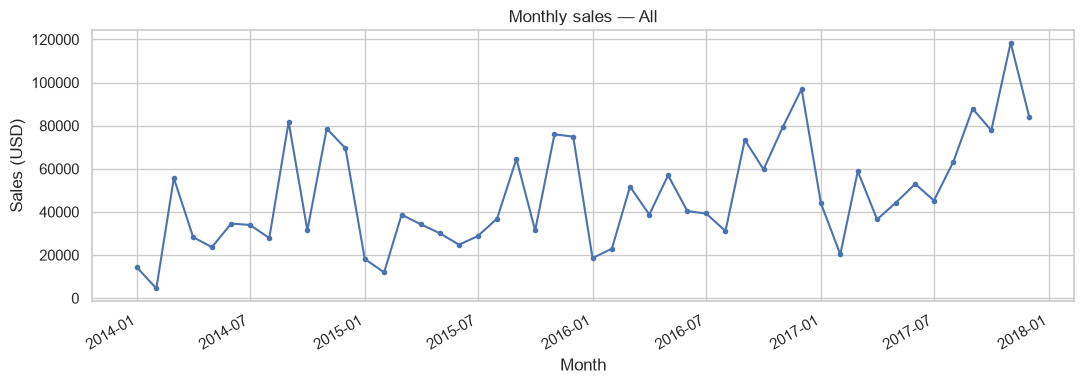

interactive(children=(Dropdown(description='Category', options=('All', 'Furniture', 'Office Supplies', 'Techno…

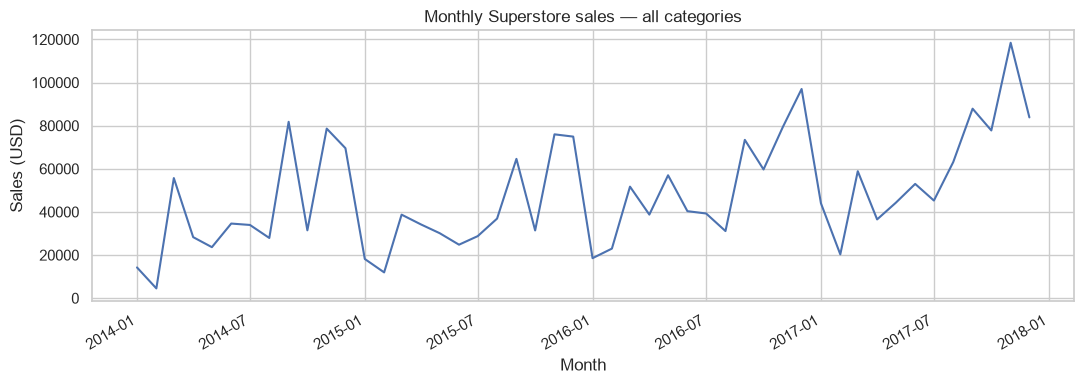

,Sales,Profit
Order Year,,
2014,484247.50,49543.97
2015,470532.51,61618.60
2016,609205.60,81795.17
2017,733215.26,93439.27


,sales_by_calendar_month
Order Month,
11,352461.0710
12,325293.5035
9,307649.9457
3,205005.4888
10,200322.9847
8,159044.0630
5,155028.8117
6,152718.6793
7,147238.0970


In [4]:
import ipywidgets as widgets
def plot_monthly_sales(category='All'):
    selected=df if category=='All' else df[df['Category']==category]
    monthly=selected.groupby('Order Month-Year')['Sales'].sum()
    index=pd.period_range(df['Order Month-Year'].min(),df['Order Month-Year'].max(),freq='M')
    monthly=monthly.reindex(index,fill_value=0)
    fig,ax=plt.subplots(figsize=(11,4))
    ax.plot(monthly.index.to_timestamp(),monthly.to_numpy(),marker='o',markersize=3)
    ax.set(title=f'Monthly sales — {category}',xlabel='Month',ylabel='Sales (USD)')
    fig.autofmt_xdate()
    plt.tight_layout();plt.show()
    return monthly
monthly=plot_monthly_sales()
widgets.interact(plot_monthly_sales,category=widgets.Dropdown(options=['All']+sorted(df['Category'].unique()),value='All',description='Category'))
fig,ax=plt.subplots(figsize=(11,4));ax.plot(monthly.index.to_timestamp(),monthly.values)
ax.set(title='Monthly Superstore sales — all categories',xlabel='Month',ylabel='Sales (USD)');fig.autofmt_xdate()
savefig('day4_superstore_monthly')
display(df.groupby('Order Year')[['Sales','Profit']].sum().round(2))
display(df.groupby('Order Month')['Sales'].sum().sort_values(ascending=False).to_frame('sales_by_calendar_month'))

## Geographic concentration: Top N slider

interactive(children=(IntSlider(value=10, description='Top N', max=25, min=5), Output()), _dom_classes=('widge…

Top five share: 0.5197216982341212


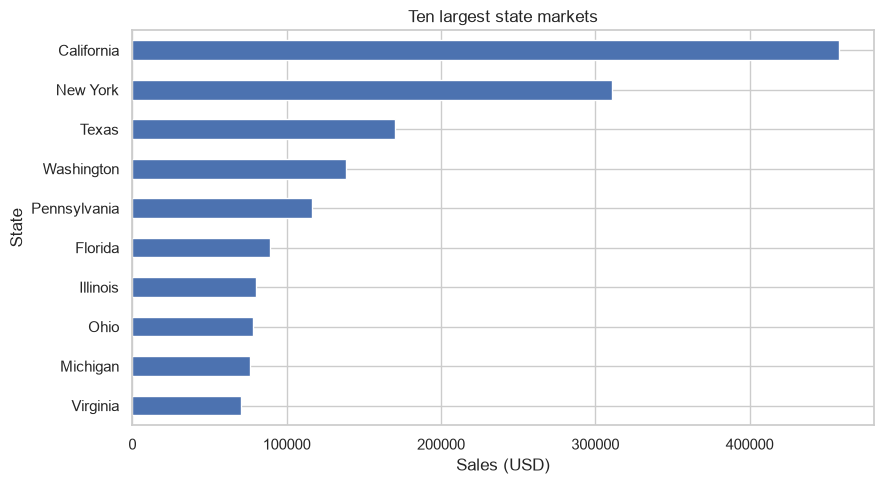

In [5]:
state_sales=df.groupby('State')['Sales'].sum().sort_values()
def plot_top_states(top_n=10):
    values=state_sales.tail(top_n)
    fig,ax=plt.subplots(figsize=(10,max(4,top_n*.28)))
    bars=ax.barh(values.index,values.values,color='steelblue')
    ax.bar_label(bars,labels=[f'${v:,.0f}' for v in values],padding=3)
    ax.set(xlabel='Sales (USD)',ylabel='State',title=f'Top {top_n} states by sales')
    ax.margins(x=.18);plt.tight_layout();plt.show()
widgets.interact(plot_top_states,top_n=widgets.IntSlider(min=5,max=min(25,len(state_sales)),value=10,description='Top N'))
print('Top five share:',state_sales.tail(5).sum()/state_sales.sum())
state_sales.tail(10).plot.barh(figsize=(9,5));plt.xlabel('Sales (USD)');plt.title('Ten largest state markets')
savefig('day4_superstore_states')

## Ten most profitable products
Group by Product ID and Product Name to avoid merging different IDs with the same name. Exact profit values are annotated.

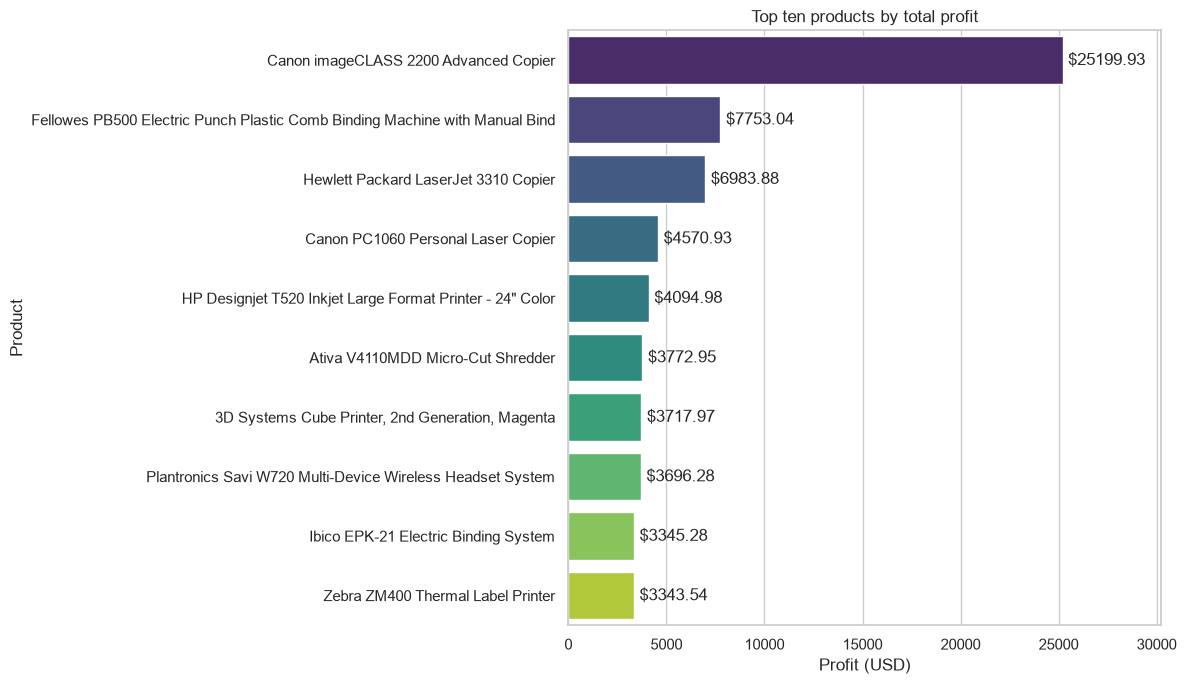

,,profit
Product ID,Product Name,
TEC-CO-10004722,Canon imageCLASS 2200 Advanced Copier,25199.9280
OFF-BI-10003527,Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,7753.0390
TEC-CO-10001449,Hewlett Packard LaserJet 3310 Copier,6983.8836
TEC-CO-10003763,Canon PC1060 Personal Laser Copier,4570.9347
TEC-MA-10001127,"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",4094.9766
TEC-MA-10003979,Ativa V4110MDD Micro-Cut Shredder,3772.9461
TEC-MA-10001047,"3D Systems Cube Printer, 2nd Generation, Magenta",3717.9714
TEC-AC-10002049,Plantronics Savi W720 Multi-Device Wireless Headset System,3696.2820
OFF-BI-10001120,Ibico EPK-21 Electric Binding System,3345.2823


In [6]:
product_profit=df.groupby(['Product ID','Product Name'])['Profit'].sum().nlargest(10)
labels=[name for _,name in product_profit.index]
fig,ax=plt.subplots(figsize=(12,7))
sns.barplot(x=product_profit.values,y=labels,hue=labels,palette='viridis',legend=False,ax=ax)
for container in ax.containers:
    ax.bar_label(container,fmt='$%.2f',padding=4)
ax.set(title='Top ten products by total profit',xlabel='Profit (USD)',ylabel='Product')
ax.margins(x=.2)
savefig('day4_superstore_products')
display(product_profit.to_frame('profit'))

## Discounts and losses
Show category colors and category-specific fitted lines, plus the overall regression. Tabulate each observed discount level by category with sample size, average profit and loss share. A threshold is a candidate for investigation, not a guaranteed safe discount or a causal estimate.

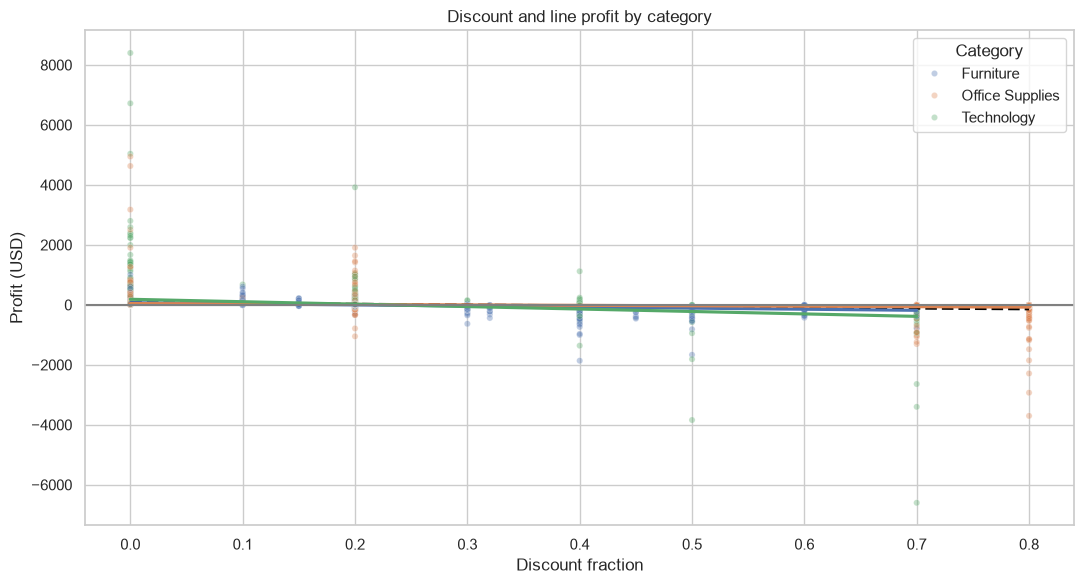

n  mean_profit  loss_share
Category        Discount                               
Furniture       0.00       836       69.537       0.000
                0.10        76       93.566       0.053
                0.15        52       27.288       0.327
                0.20       615       10.189       0.270
                0.30       222      -48.177       0.932
                0.32        27      -88.561       1.000
                0.40        75     -215.832       1.000
                0.45        11     -226.646       1.000
                0.50        54     -238.356       1.000
                0.60       138      -43.077       1.000
                0.70        15     -259.663       1.000
Office Supplies 0.00      3129       41.709       0.000
                0.10        16       67.880       0.000
                0.20      2201       17.282       0.094
                0.70       380      -43.687       1.000
                0.80       300     -101.797       1.000
Technology      0.00       833      158.882       0.000
                0.10         2      416.042       0.000
                0.20       841       54.736       0.155
                0.30         5       65.208       0.200
                0.40       131      -52.440       0.802
                0.50        12     -636.269       1.000
                0.70        23     -851.275       1.000

,count,mean,sum
Category,,,
Furniture,542,-100.512465,-54477.7561
Office Supplies,680,-69.323732,-47140.1376
Technology,171,-197.416154,-33758.1623


High discount (>20%) loss share: 0.9676956209619526


In [7]:
fig,ax=plt.subplots(figsize=(11,6))
sns.scatterplot(data=df,x='Discount',y='Profit',hue='Category',alpha=.35,s=20,ax=ax)
sns.regplot(data=df,x='Discount',y='Profit',scatter=False,ci=None,color='black',ax=ax,line_kws={'linestyle':'--','label':'Overall fit'})
for category,color in zip(sorted(df['Category'].unique()),sns.color_palette(n_colors=3)):
    sns.regplot(data=df[df['Category']==category],x='Discount',y='Profit',scatter=False,ci=None,color=color,ax=ax)
ax.axhline(0,color='grey');ax.set(title='Discount and line profit by category',xlabel='Discount fraction',ylabel='Profit (USD)')
savefig('day4_superstore_discounts')
discounts=df.assign(Loss=df['Profit']<0).groupby(['Category','Discount']).agg(n=('Profit','size'),mean_profit=('Profit','mean'),loss_share=('Loss','mean'))
display(discounts.round(3))
discounts.to_csv(ROOT/'day4'/'discount_diagnostics.csv')
high=df[df['Discount']>.2]
display(high.groupby('Category')['Profit'].agg(['count','mean','sum']))
print('High discount (>20%) loss share:',(high['Profit']<0).mean())

## Tooling review — Matplotlib and Seaborn
Matplotlib offers direct control of axes, annotations and layouts; it works well with explicit widget callbacks. Seaborn expresses grouped and statistical plots succinctly and handles semantic colors and legends. Both integrate with ipywidgets through Python callbacks; interactivity is not exclusive to either. Rendering speed depends on the chart, backend and data, so one timing is not a general performance claim. Here Matplotlib fits the custom time/state charts and Seaborn fits the grouped discount comparison. For executive communication, titles, units, denominators and restrained color choices matter more than library choice.

## Executive summary — computed findings and actions

In [8]:
total_sales=df['Sales'].sum();total_profit=df['Profit'].sum()
annual=df.groupby('Order Year')['Sales'].sum()
best_month=int(df.groupby('Order Month')['Sales'].sum().idxmax())
top_category=df.groupby('Category')['Sales'].sum().idxmax()
summary=f"""# Executive summary

- Revenue is ${total_sales:,.2f}; profit is ${total_profit:,.2f}; aggregate profit margin is {total_profit/total_sales:.2%}.
- {state_sales.index[-1]} is the largest state market (${state_sales.iloc[-1]:,.2f}); the top five states account for {state_sales.tail(5).sum()/total_sales:.1%} of revenue. Protect availability in these markets while evaluating profit, not revenue alone.
- {top_category} leads category sales. The most profitable product is {product_profit.index[0][1]}, contributing ${product_profit.iloc[0]:,.2f}. Review stock availability and concentration risk.
- Sales change from ${annual.iloc[0]:,.0f} in {annual.index[0]} to ${annual.iloc[-1]:,.0f} in {annual.index[-1]}; calendar month {best_month} has the largest pooled sales. Plan inventory around recurring peaks, but distinguish year growth from seasonal effects.
- {(high['Profit']<0).mean():.1%} of order lines discounted above 20% lose money. Review category-specific high-discount promotions and run a controlled pilot before imposing a universal cap; observed association is not causal.

Limitations: this historical sample is not current store performance. Returns, acquisition cost, inventory constraints and exposure are not fully modeled. Validate margin definitions and test the promotion hypothesis with appropriate controls.
"""
from IPython.display import Markdown
display(Markdown(summary))
(ROOT/'day4'/'executive_summary.md').write_text(summary)
print('All notebook analyses completed.')

# Executive summary

- Revenue is $2,297,200.86; profit is $286,397.02; aggregate profit margin is 12.47%.
- California is the largest state market ($457,687.63); the top five states account for 52.0% of revenue. Protect availability in these markets while evaluating profit, not revenue alone.
- Technology leads category sales. The most profitable product is Canon imageCLASS 2200 Advanced Copier, contributing $25,199.93. Review stock availability and concentration risk.
- Sales change from $484,247 in 2014 to $733,215 in 2017; calendar month 11 has the largest pooled sales. Plan inventory around recurring peaks, but distinguish year growth from seasonal effects.
- 96.8% of order lines discounted above 20% lose money. Review category-specific high-discount promotions and run a controlled pilot before imposing a universal cap; observed association is not causal.

Limitations: this historical sample is not current store performance. Returns, acquisition cost, inventory constraints and exposure are not fully modeled. Validate margin definitions and test the promotion hypothesis with appropriate controls.


All notebook analyses completed.
